<a href="https://colab.research.google.com/github/280149-prog/Lab2_Cuda/blob/main/Lab2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import numpy as np
import time
N = 1024
A_cpu = np.random.rand(N, N).astype(np.float32)
B_cpu = np.random.rand(N, N).astype(np.float32)
start = time.time()
C_cpu = np.matmul(A_cpu, B_cpu)
end = time.time()
print(f"Mnożenie macierzy na CPU trwało: {end - start:.5f} sekund.")

Mnożenie macierzy na CPU trwało: 0.01834 sekund.


In [ ]:
import numpy as np
import cupy as cp
import time
N = 1024
A_cpu = np.random.rand(N, N).astype(np.float32)
B_cpu = np.random.rand(N, N).astype(np.float32)
A_gpu = cp.array(A_cpu)
B_gpu = cp.array(B_cpu)
start = time.time()
C_gpu = cp.matmul(A_gpu, B_gpu)
cp.cuda.Stream.null.synchronize()  # Synchronizacja z GPU
del A_gpu, B_gpu, C_gpu
end = time.time()
print(f"Mnożenie macierzy na GPU trwało: {end - start:.5f} sekund.")

Mnożenie macierzy na GPU trwało: 0.00115 sekund.


In [ ]:
import locale
locale.getpreferredencoding = lambda: "UTF-8"
import pycuda.driver as cuda
import pycuda.autoinit
from pycuda.compiler import SourceModule
import numpy as np
import time

kernel_code = """
__global__ void matrixMul(float *A, float *B, float *C, int N) {
    int row = blockIdx.y * blockDim.y + threadIdx.y;
    int col = blockIdx.x * blockDim.x + threadIdx.x;
    float sum = 0.0;
    if(row < N && col < N) {
        for (int k = 0; k < N; k++) {
            sum += A[row * N + k] * B[k * N + col];
        }
        C[row * N + col] = sum;
    }
}
"""
N = 1024
mod = SourceModule(kernel_code)
matrixMul = mod.get_function("matrixMul")
A_cpu = np.empty((N, N), np.float32)
B_cpu = np.empty((N, N), np.float32)
C_cpu = np.empty((N, N), np.float32)
A_gpu = cuda.mem_alloc(A_cpu.nbytes)
B_gpu = cuda.mem_alloc(A_cpu.nbytes)
C_gpu = cuda.mem_alloc(A_cpu.nbytes)
start = time.time()
cuda.memcpy_htod(A_gpu, A_cpu)
block_size = (32, 32, 1)
grid_size = (int(N/32), int(N/32), 1)
matrixMul(A_gpu, B_gpu, C_gpu, np.int32(N), block=block_size, grid=grid_size)
cuda.Context.synchronize()
cuda.memcpy_dtoh(C_cpu, C_gpu)
del A_gpu, B_gpu, C_gpu
end = time.time()
print(f"Mnożenie macierzy na GPU trwało: {end - start:.5f} sekund.")

Mnożenie macierzy na GPU trwało: 0.01129 sekund.


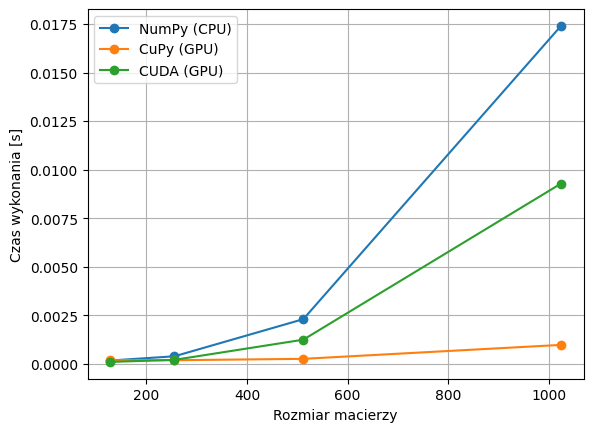

In [ ]:
import numpy as np
import cupy as cp
import time
import matplotlib.pyplot as plt
import pycuda.driver as cuda
import pycuda.autoinit
from pycuda.compiler import SourceModule
import gc

kernel_code = """
__global__ void matrixMul(float *A, float *B, float *C, int N) {
    int row = blockIdx.y * blockDim.y + threadIdx.y;
    int col = blockIdx.x * blockDim.x + threadIdx.x;

    if (row < N && col < N) {
        float sum = 0.0;
        for (int k = 0; k < N; k++) {
            sum += A[row * N + k] * B[k * N + col];
        }
        C[row * N + col] = sum;
    }
}
"""

mod = SourceModule(kernel_code)
matrixMul = mod.get_function("matrixMul")

sizes = [128, 256, 512, 1024]
numpy_times = []
cupy_times = []
cuda_times = []

for N in sizes:
    A = np.random.rand(N, N).astype(np.float32)
    B = np.random.rand(N, N).astype(np.float32)

    start = time.time()
    C = np.matmul(A, B)
    numpy_times.append(time.time() - start)

    A_gpu = cp.array(A)
    B_gpu = cp.array(B)

    cp.cuda.Stream.null.synchronize()
    start = time.time()
    C_gpu = cp.matmul(A_gpu, B_gpu)
    cp.cuda.Stream.null.synchronize()
    cupy_times.append(time.time() - start)

    C_cuda = np.empty((N, N), dtype=np.float32)

    A_cuda = cuda.mem_alloc(A.nbytes)
    B_cuda = cuda.mem_alloc(B.nbytes)
    C_cuda_gpu = cuda.mem_alloc(C_cuda.nbytes)

    cuda.memcpy_htod(A_cuda, A)
    cuda.memcpy_htod(B_cuda, B)

    block_size = (16, 16, 1)
    grid_size = ((N + 15) // 16, (N + 15) // 16, 1)

    start = time.time()
    matrixMul(
        A_cuda, B_cuda, C_cuda_gpu, np.int32(N),
        block=block_size, grid=grid_size
    )
    cuda.Context.synchronize()
    cuda_times.append(time.time() - start)

    cuda.memcpy_dtoh(C_cuda, C_cuda_gpu)

    del A_gpu, B_gpu, C_gpu
    del A_cuda, B_cuda, C_cuda_gpu
    del A, B, C, C_cuda

plt.plot(sizes, numpy_times, marker="o", label="NumPy (CPU)")
plt.plot(sizes, cupy_times, marker="o", label="CuPy (GPU)")
plt.plot(sizes, cuda_times, marker="o", label="CUDA (GPU)")
plt.xlabel("Rozmiar macierzy")
plt.ylabel("Czas wykonania [s]")
plt.legend()
plt.grid()
plt.show()